<a href="https://colab.research.google.com/github/shivani-shambhavi/AI-Mood-Based-Movie-Recommender_/blob/main/Student%20Performance%20and%20Statistical%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Q1. Student Performance and Statistical Analysis

In [7]:

# ==========================================
# Q1: STUDENT PERFORMANCE AND STATISTICAL ANALYSIS
# ==========================================

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set graph style
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:

# Upload CSV file in Google Colab

from google.colab import files

uploaded = files.upload()

# Read uploaded CSV file
df = pd.read_csv("StudentsPerformance.csv")

# Display first 5 records
print("First 5 Student Records:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Display number of rows and columns
print("\nDataset Shape:", df.shape)


Saving StudentsPerformance.csv to StudentsPerformance (1).csv
First 5 Student Records:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
None

Dataset Shape: (1000, 8)


In [9]:

# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Handle missing values
# Fill numerical columns with median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical columns with mode
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)


Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate Records: 0

Missing Values After Cleaning:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Dataset Shape After Cleaning: (1000, 8)


In [10]:

# Select numerical columns
scores = ["math score", "reading score", "writing score"]

# Calculate mean
mean_values = df[scores].mean()

# Calculate median
median_values = df[scores].median()

# Calculate mode
mode_values = df[scores].mode().iloc[0]

# Create statistical comparison table
central_tendency = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Mode": mode_values
})

print("Mean, Median and Mode:")
display(central_tendency)

# Interpretation
print("\nInterpretation:")
print("Mean represents the average marks.")
print("Median represents the middle value.")
print("Mode represents the most frequently occurring value.")


Mean, Median and Mode:


,Mean,Median,Mode
math score,66.089,66.0,65
reading score,69.169,70.0,72
writing score,68.054,69.0,74



Interpretation:
Mean represents the average marks.
Median represents the middle value.
Mode represents the most frequently occurring value.


In [11]:

# Calculate Q1, Q2 and Q3

quartiles = df[scores].quantile([0.25, 0.50, 0.75])

print("Quartiles:")
display(quartiles)

# Calculate percentiles
percentiles = df[scores].quantile([0.10, 0.25, 0.50, 0.75, 0.90])

print("\nPercentiles:")
display(percentiles)

# Calculate IQR
Q1 = df[scores].quantile(0.25)
Q3 = df[scores].quantile(0.75)

IQR = Q3 - Q1

print("\nInterquartile Range:")
print(IQR)

# Calculate Range
data_range = df[scores].max() - df[scores].min()

print("\nRange:")
print(data_range)


Quartiles:


,math score,reading score,writing score
0.25,57.0,59.0,57.75
0.50,66.0,70.0,69.00
0.75,77.0,79.0,79.00



Percentiles:


,math score,reading score,writing score
0.10,47.0,51.0,48.00
0.25,57.0,59.0,57.75
0.50,66.0,70.0,69.00
0.75,77.0,79.0,79.00
0.90,86.0,87.1,87.00



Interquartile Range:
math score       20.00
reading score    20.00
writing score    21.25
dtype: float64

Range:
math score       100
reading score     83
writing score     90
dtype: int64


In [12]:

# Calculate variance
variance = df[scores].var()

# Calculate standard deviation
std_dev = df[scores].std()

# Calculate mean
mean = df[scores].mean()

# Calculate coefficient of variation
cv = (std_dev / mean) * 100

# Create summary table
variability = pd.DataFrame({
    "Mean": mean,
    "Variance": variance,
    "Standard Deviation": std_dev,
    "Coefficient of Variation (%)": cv
})

print("Variability Analysis:")
display(variability)

print("\nInterpretation:")
print("Higher CV means greater relative variability.")
print("Lower CV means more consistent marks.")


Variability Analysis:


,Mean,Variance,Standard Deviation,Coefficient of Variation (%)
math score,66.089,229.918998,15.163080,22.943425
reading score,69.169,213.165605,14.600192,21.107999
writing score,68.054,230.907992,15.195657,22.328823



Interpretation:
Higher CV means greater relative variability.
Lower CV means more consistent marks.


In [13]:

# Calculate Q1 and Q3
Q1 = df[scores].quantile(0.25)
Q3 = df[scores].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limits:")
print(lower_limit)

print("\nUpper Limits:")
print(upper_limit)

# Identify outliers
outlier_mask = (
    (df[scores] < lower_limit) |
    (df[scores] > upper_limit)
)

print("\nOutliers in Each Subject:")
print(outlier_mask.sum())

# Display outlier records
outliers = df[outlier_mask.any(axis=1)]

print("\nOutlier Records:")
display(outliers)

# Compare statistics before and after removing outliers
clean_scores = df[scores][~outlier_mask.any(axis=1)]

comparison = pd.DataFrame({
    "Original Mean": df[scores].mean(),
    "Mean Without Outliers": clean_scores.mean(),
    "Original Std": df[scores].std(),
    "Std Without Outliers": clean_scores.std()
})

print("\nImpact of Outliers:")
display(comparison)


Lower Limits:
math score       27.000
reading score    29.000
writing score    25.875
dtype: float64

Upper Limits:
math score       107.000
reading score    109.000
writing score    110.875
dtype: float64

Outliers in Each Subject:
math score       8
reading score    6
writing score    5
dtype: int64

Outlier Records:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
76,male,group E,some high school,standard,none,30,26,22
145,female,group C,some college,free/reduced,none,22,39,33
211,male,group C,some college,free/reduced,none,35,28,27
327,male,group A,some college,free/reduced,none,28,23,19
338,female,group B,some high school,free/reduced,none,24,38,27
466,female,group D,associate's degree,free/reduced,none,26,31,38
596,male,group B,high school,free/reduced,none,30,24,15
787,female,group B,some college,standard,none,19,38,32



Impact of Outliers:


,Original Mean,Mean Without Outliers,Original Std,Std Without Outliers
math score,66.089,66.625506,15.163080,14.409394
reading score,69.169,69.640688,14.600192,14.016760
writing score,68.054,68.566802,15.195657,14.525267


In [14]:

# Compare Math, Reading and Writing scores

comparison_cv = pd.DataFrame({
    "Mean": df[scores].mean(),
    "Standard Deviation": df[scores].std(),
    "CV (%)": (df[scores].std() / df[scores].mean()) * 100
})

print("Subject Variability Comparison:")
display(comparison_cv)

# Identify subject with highest and lowest variability
highest = comparison_cv["CV (%)"].idxmax()
lowest = comparison_cv["CV (%)"].idxmin()

print("\nHighest Variability:", highest)
print("Lowest Variability:", lowest)


Subject Variability Comparison:


,Mean,Standard Deviation,CV (%)
math score,66.089,15.163080,22.943425
reading score,69.169,14.600192,21.107999
writing score,68.054,15.195657,22.328823



Highest Variability: math score
Lowest Variability: reading score


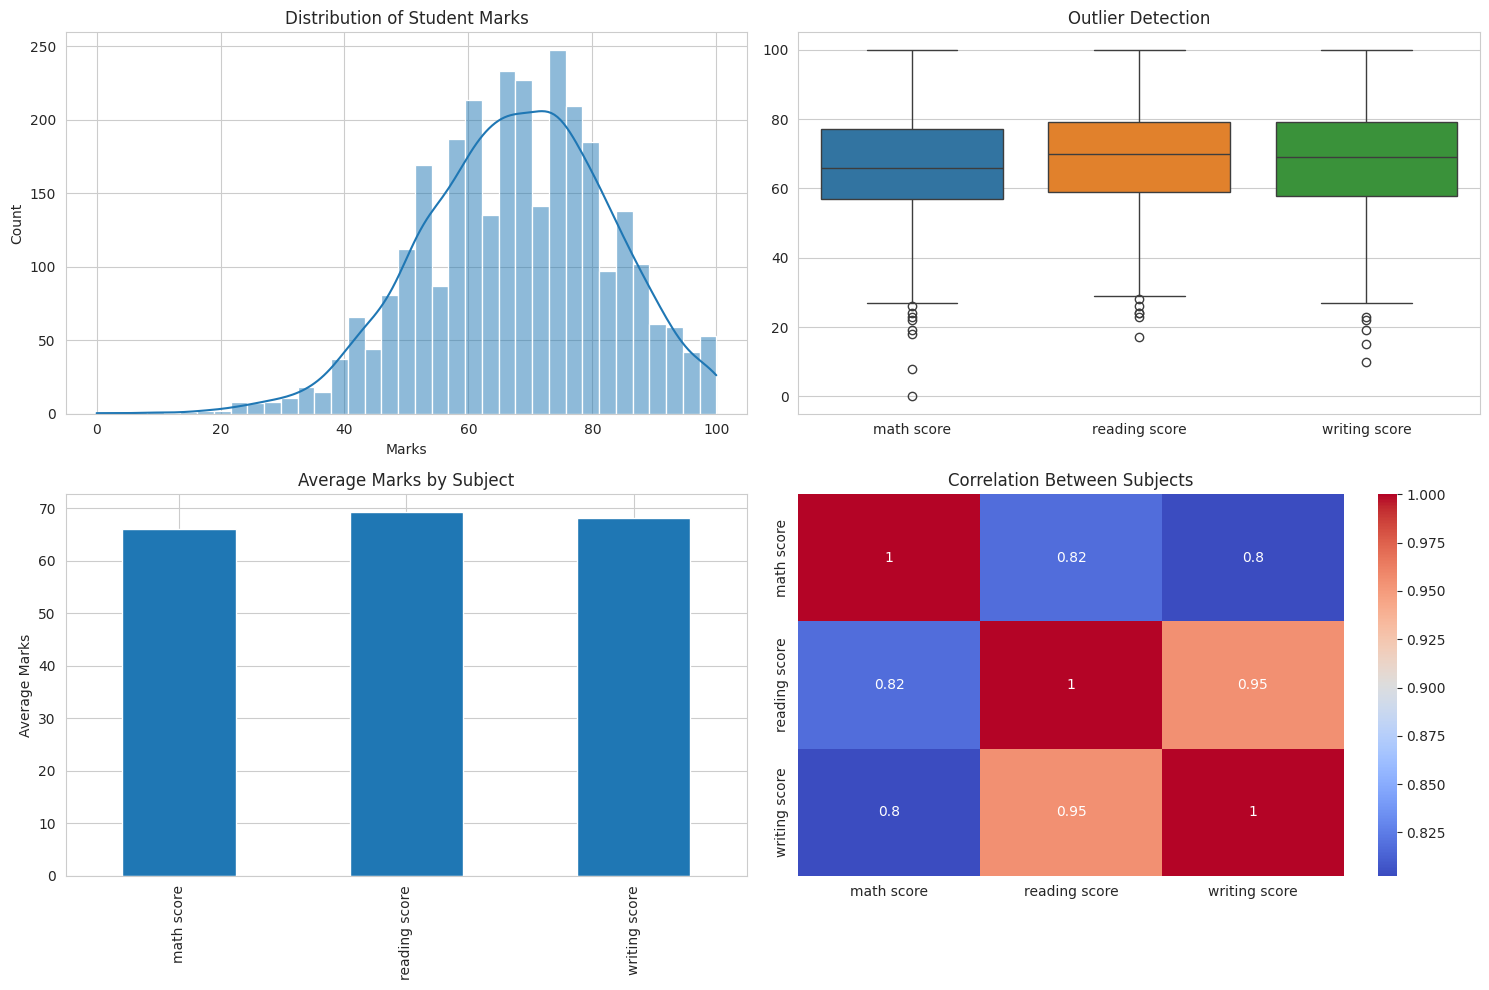

In [15]:

# Create statistical dashboard

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Distribution of marks
sns.histplot(
    df[scores].melt()["value"],
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Student Marks")
axes[0, 0].set_xlabel("Marks")

# 2. Boxplot
sns.boxplot(data=df[scores], ax=axes[0, 1])
axes[0, 1].set_title("Outlier Detection")

# 3. Comparison of average marks
df[scores].mean().plot(
    kind="bar",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Marks by Subject")
axes[1, 0].set_ylabel("Average Marks")

# 4. Correlation heatmap
sns.heatmap(
    df[scores].corr(),
    annot=True,
    cmap="coolwarm",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation Between Subjects")

plt.tight_layout()
plt.show()


Correlation Matrix:


,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


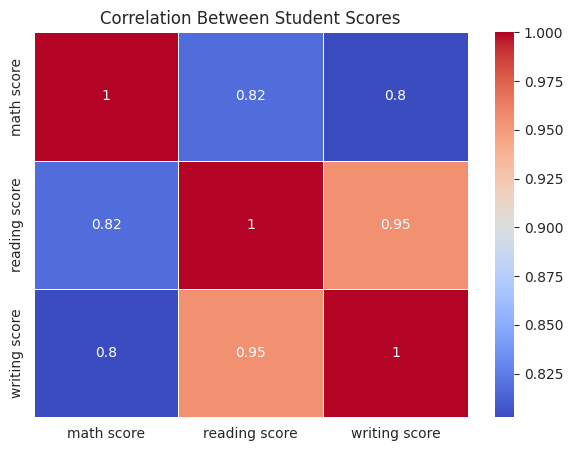


Interpretation:
Correlation close to +1 indicates a strong positive relationship.
Correlation close to -1 indicates a strong negative relationship.
Correlation close to 0 indicates a weak linear relationship.


In [16]:

# Calculate correlation between subjects

correlation = df[scores].corr()

print("Correlation Matrix:")
display(correlation)

# Visualize correlation
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Between Student Scores")
plt.show()

print("\nInterpretation:")
print("Correlation close to +1 indicates a strong positive relationship.")
print("Correlation close to -1 indicates a strong negative relationship.")
print("Correlation close to 0 indicates a weak linear relationship.")


The student performance dataset contains 1,000 records. Data cleaning was performed by checking missing values and duplicate records. Mean, median, mode, quartiles, percentiles, IQR, range, variance, standard deviation and coefficient of variation were calculated. Outliers were identified using the IQR method, and their impact on statistical measures was analyzed. Math, reading and writing marks were compared using statistical visualizations. Correlation analysis was used to understand relationships between subjects. The dataset does not contain study hours or attendance, so their relationship with academic performance could not be directly evaluated.

##Q2. Probability Distribution and CLT Simulation

In [17]:

# ==========================================
# Q2: PROBABILITY DISTRIBUTION AND CLT
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    norm, uniform, binom, poisson,
    shapiro
)

np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [18]:

# Generate Normal Distribution
normal_data = np.random.normal(
    loc=50,
    scale=10,
    size=10000
)

# Generate Uniform Distribution
uniform_data = np.random.uniform(
    low=0,
    high=100,
    size=10000
)

# Generate Binomial Distribution
binomial_data = np.random.binomial(
    n=10,
    p=0.5,
    size=10000
)

# Generate Poisson Distribution
poisson_data = np.random.poisson(
    lam=5,
    size=10000
)

print("All four distributions generated successfully!")


All four distributions generated successfully!


In [19]:

# Calculate theoretical values

theoretical_mean = {
    "Normal": 50,
    "Uniform": (0 + 100) / 2,
    "Binomial": 10 * 0.5,
    "Poisson": 5
}

theoretical_variance = {
    "Normal": 10**2,
    "Uniform": (100 - 0)**2 / 12,
    "Binomial": 10 * 0.5 * (1 - 0.5),
    "Poisson": 5
}

# Store generated data
distributions = {
    "Normal": normal_data,
    "Uniform": uniform_data,
    "Binomial": binomial_data,
    "Poisson": poisson_data
}

# Calculate experimental values
results = []

for name, data in distributions.items():

    results.append({
        "Distribution": name,
        "Theoretical Mean": theoretical_mean[name],
        "Experimental Mean": np.mean(data),
        "Theoretical Variance": theoretical_variance[name],
        "Experimental Variance": np.var(data)
    })

distribution_results = pd.DataFrame(results)

print("Theoretical vs Experimental Results:")
display(distribution_results)


Theoretical vs Experimental Results:


,Distribution,Theoretical Mean,Experimental Mean,Theoretical Variance,Experimental Variance
0,Normal,50.0,49.978640,100.000000,100.683606
1,Uniform,50.0,50.713457,833.333333,838.052472
2,Binomial,5.0,4.990000,2.500000,2.452700
3,Poisson,5.0,5.004500,5.000000,5.016080


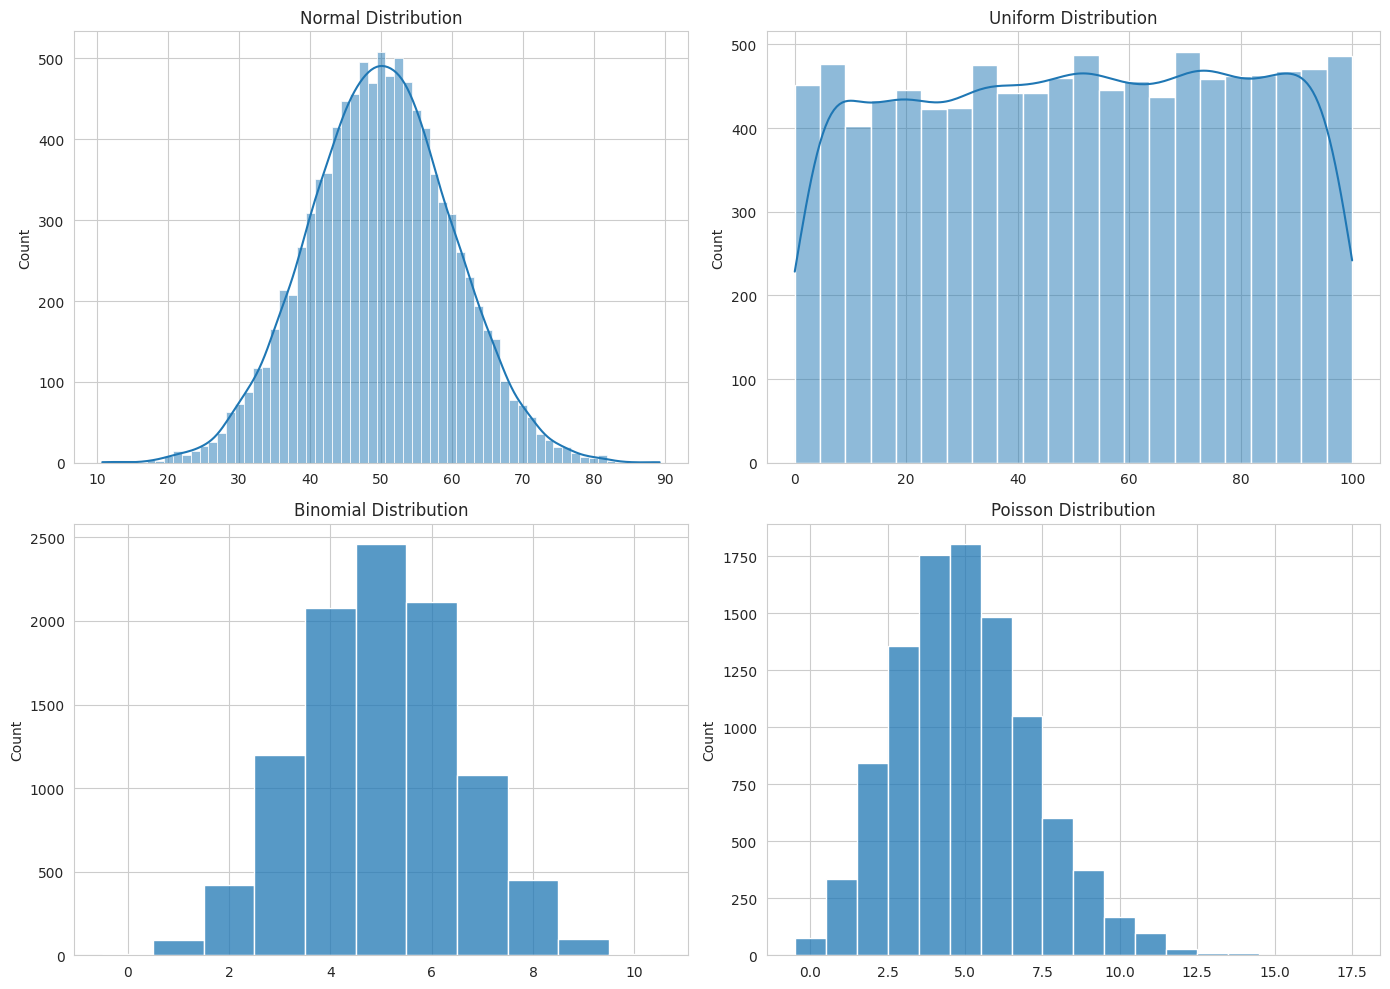

In [20]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Normal Distribution
sns.histplot(
    normal_data,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Normal Distribution")

# Uniform Distribution
sns.histplot(
    uniform_data,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Uniform Distribution")

# Binomial Distribution
sns.histplot(
    binomial_data,
    discrete=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Binomial Distribution")

# Poisson Distribution
sns.histplot(
    poisson_data,
    discrete=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Poisson Distribution")

plt.tight_layout()
plt.show()


In [21]:

# Normal Distribution
# P(40 < X < 60)

normal_probability = (
    norm.cdf(60, loc=50, scale=10) -
    norm.cdf(40, loc=50, scale=10)
)

# Uniform Distribution
# P(20 < X < 60)

uniform_probability = (
    uniform.cdf(60, loc=0, scale=100) -
    uniform.cdf(20, loc=0, scale=100)
)

# Binomial Distribution
# P(3 <= X <= 7)

binomial_probability = (
    binom.cdf(7, n=10, p=0.5) -
    binom.cdf(2, n=10, p=0.5)
)

# Poisson Distribution
# P(3 <= X <= 7)

poisson_probability = (
    poisson.cdf(7, mu=5) -
    poisson.cdf(2, mu=5)
)

print("Probability Results:")

print("Normal P(40 < X < 60):",
      normal_probability)

print("Uniform P(20 < X < 60):",
      uniform_probability)

print("Binomial P(3 <= X <= 7):",
      binomial_probability)

print("Poisson P(3 <= X <= 7):",
      poisson_probability)


Probability Results:
Normal P(40 < X < 60): 0.6826894921370859
Uniform P(20 < X < 60): 0.39999999999999997
Binomial P(3 <= X <= 7): 0.890625
Poisson P(3 <= X <= 7): 0.7419763064469114


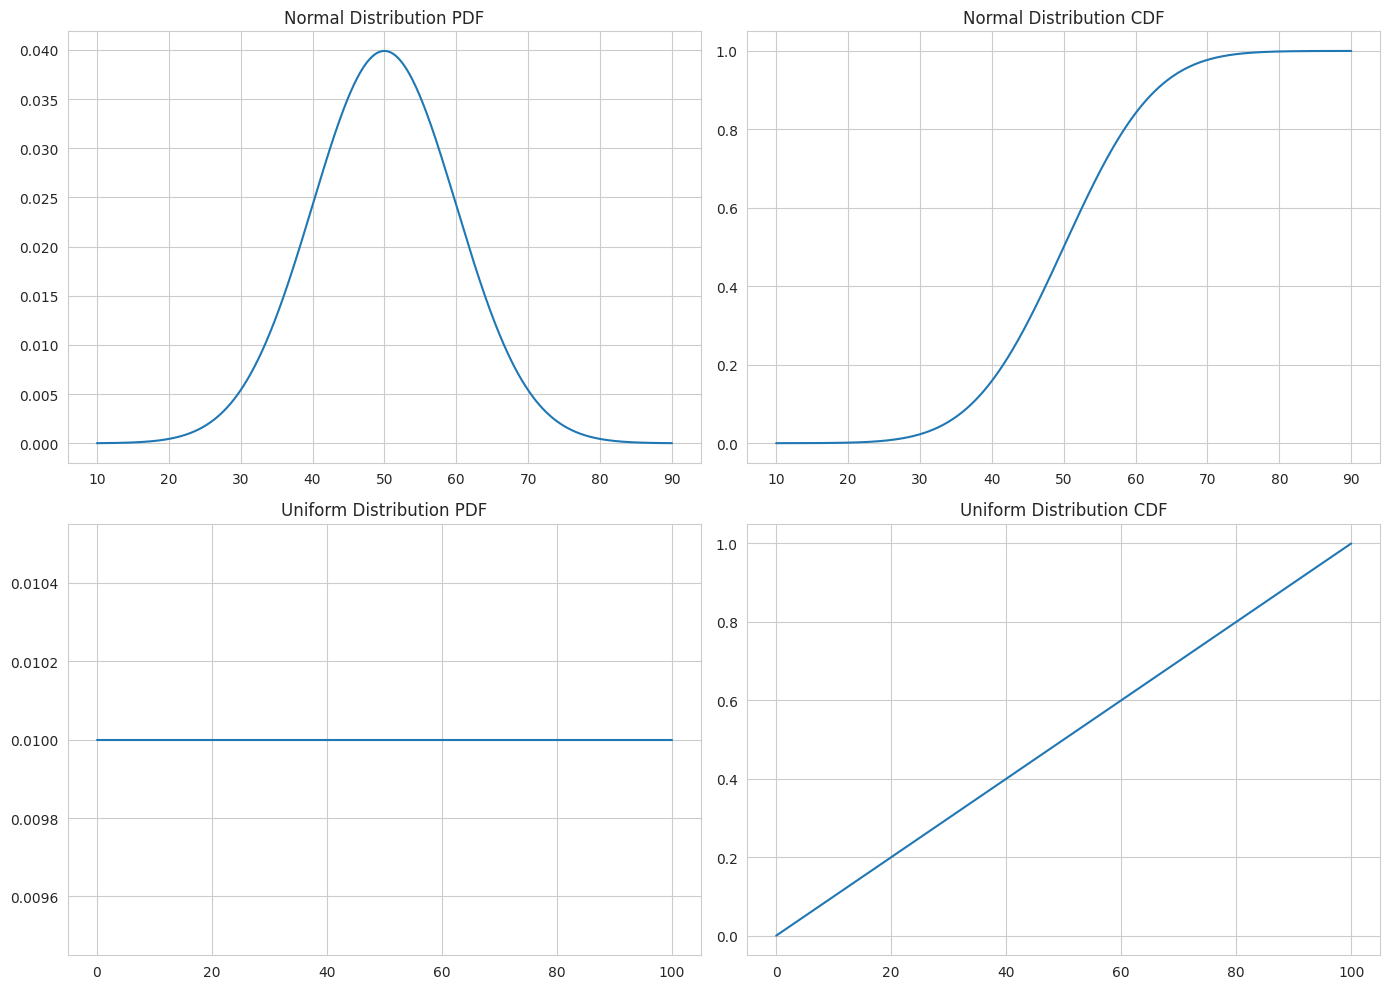

In [22]:

# Create values for PDF and CDF

x_normal = np.linspace(10, 90, 500)
x_uniform = np.linspace(0, 100, 500)

# Calculate PDF
normal_pdf = norm.pdf(
    x_normal,
    loc=50,
    scale=10
)

uniform_pdf = uniform.pdf(
    x_uniform,
    loc=0,
    scale=100
)

# Calculate CDF
normal_cdf = norm.cdf(
    x_normal,
    loc=50,
    scale=10
)

uniform_cdf = uniform.cdf(
    x_uniform,
    loc=0,
    scale=100
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Normal PDF
axes[0, 0].plot(x_normal, normal_pdf)
axes[0, 0].set_title("Normal Distribution PDF")

# Normal CDF
axes[0, 1].plot(x_normal, normal_cdf)
axes[0, 1].set_title("Normal Distribution CDF")

# Uniform PDF
axes[1, 0].plot(x_uniform, uniform_pdf)
axes[1, 0].set_title("Uniform Distribution PDF")

# Uniform CDF
axes[1, 1].plot(x_uniform, uniform_cdf)
axes[1, 1].set_title("Uniform Distribution CDF")

plt.tight_layout()
plt.show()


In [23]:

# Generate original population of customer waiting times

population = np.random.exponential(
    scale=10,
    size=100000
)

print("Population Mean:", np.mean(population))
print("Population Standard Deviation:", np.std(population))

# Sample sizes
sample_sizes = [5, 30, 50, 100]

# Number of samples
number_of_samples = 5000

# Store sample means
sampling_means = {}

for n in sample_sizes:

    means = []

    for i in range(number_of_samples):

        sample = np.random.choice(
            population,
            size=n,
            replace=True
        )

        means.append(np.mean(sample))

    sampling_means[n] = means

print("CLT Simulation Completed!")


Population Mean: 10.028632364573166
Population Standard Deviation: 10.022570699377763
CLT Simulation Completed!


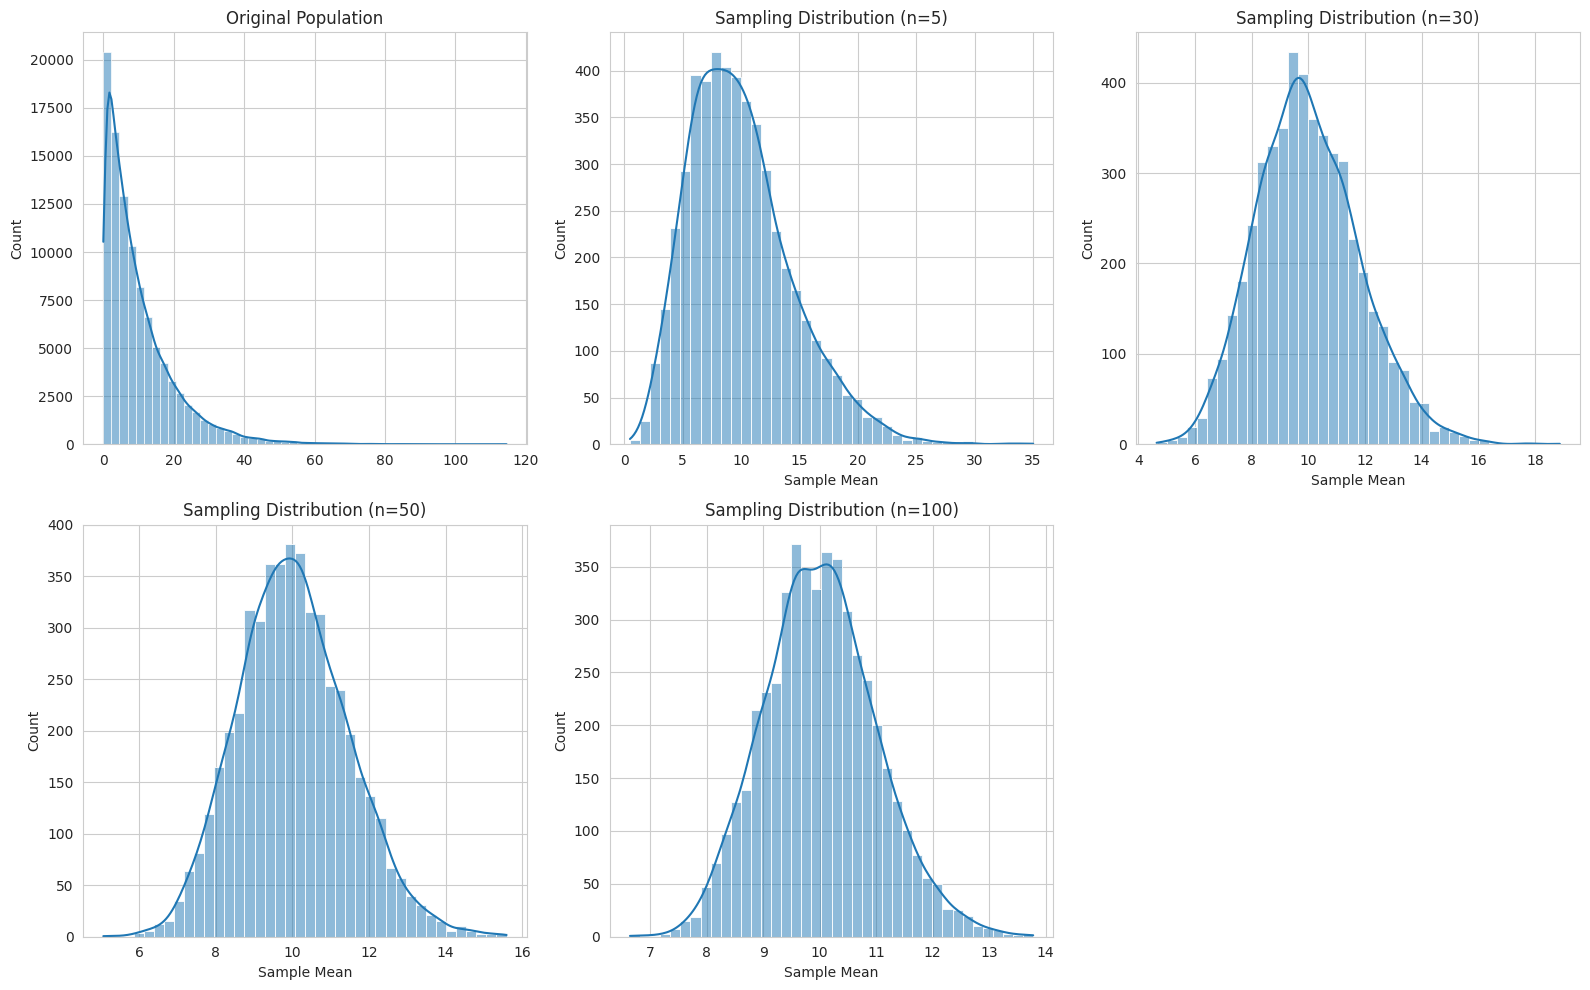

In [24]:

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Original population
sns.histplot(
    population,
    bins=50,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Original Population")

# Sampling distributions
for ax, n in zip(
    [axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]],
    sample_sizes
):

    sns.histplot(
        sampling_means[n],
        kde=True,
        bins=40,
        ax=ax
    )

    ax.set_title(f"Sampling Distribution (n={n})")
    ax.set_xlabel("Sample Mean")

# Compare means
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()


In [25]:

# Calculate sampling distribution statistics

clt_results = []

for n in sample_sizes:

    means = np.array(sampling_means[n])

    clt_results.append({
        "Sample Size": n,
        "Mean of Sample Means": np.mean(means),
        "Standard Deviation of Means": np.std(means),
        "Theoretical Standard Error": 10 / np.sqrt(n)
    })

clt_table = pd.DataFrame(clt_results)

print("CLT Results:")
display(clt_table)


CLT Results:


,Sample Size,Mean of Sample Means,Standard Deviation of Means,Theoretical Standard Error
0,5,9.935376,4.405544,4.472136
1,30,9.989762,1.809539,1.825742
2,50,10.030561,1.442834,1.414214
3,100,10.010644,0.998719,1.000000


In [26]:

# Test original population and sampling distributions

# Shapiro-Wilk supports a maximum of 5000 observations
print("Shapiro-Wilk Normality Test\n")

original_test = shapiro(population[:5000])

print("Original Population:")
print("Statistic:", original_test.statistic)
print("P-value:", original_test.pvalue)

if original_test.pvalue < 0.05:
    print("Result: Reject H0 - Data is not normally distributed")
else:
    print("Result: Fail to reject H0 - No evidence against normality")

# Test sampling distributions
for n in sample_sizes:

    test = shapiro(sampling_means[n])

    print(f"\nSample Size: {n}")
    print("Statistic:", test.statistic)
    print("P-value:", test.pvalue)

    if test.pvalue < 0.05:
        print("Reject H0: Not normally distributed")
    else:
        print("Fail to reject H0: No evidence against normality")


Shapiro-Wilk Normality Test

Original Population:
Statistic: 0.8091494872840792
P-value: 1.0449004890783082e-60
Result: Reject H0 - Data is not normally distributed

Sample Size: 5
Statistic: 0.9627922220326016
P-value: 4.989125295134046e-34
Reject H0: Not normally distributed

Sample Size: 30
Statistic: 0.9928751895028621
P-value: 3.9999966266071054e-15
Reject H0: Not normally distributed

Sample Size: 50
Statistic: 0.9955096956953526
P-value: 2.759093937586934e-11
Reject H0: Not normally distributed

Sample Size: 100
Statistic: 0.9969464858099535
P-value: 1.4747849950177237e-08
Reject H0: Not normally distributed


Four probability distributions, Normal, Uniform, Binomial and Poisson, were generated using NumPy. Theoretical and experimental means and variances were calculated and compared. Probability calculations were performed using SciPy. PDF and CDF graphs were plotted for continuous distributions. The Central Limit Theorem was demonstrated using an exponential population and different sample sizes of 5, 30, 50 and 100. As sample size increases, the sampling distribution of sample means becomes more approximately normal and its standard error decreases. Shapiro-Wilk testing was used to examine normality.

##Q3. Inferential Statistics and Hypothesis Testing

In [27]:

# ==========================================
# Q3: INFERENTIAL STATISTICS AND HYPOTHESIS TESTING
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Given dataset

batch_A = np.array([
    65, 70, 72, 75, 78,
    80, 74, 77, 69, 76
])

batch_B = np.array([
    60, 68, 72, 75, 85,
    90, 65, 80, 88, 77
])

print("Batch A:", batch_A)
print("Batch B:", batch_B)

print("\nNumber of Students in Batch A:", len(batch_A))
print("Number of Students in Batch B:", len(batch_B))


Batch A: [65 70 72 75 78 80 74 77 69 76]
Batch B: [60 68 72 75 85 90 65 80 88 77]

Number of Students in Batch A: 10
Number of Students in Batch B: 10


In [28]:

# Calculate statistics for Batch A

mean_A = np.mean(batch_A)
median_A = np.median(batch_A)
std_A = np.std(batch_A, ddof=1)

# Calculate statistics for Batch B

mean_B = np.mean(batch_B)
median_B = np.median(batch_B)
std_B = np.std(batch_B, ddof=1)

# Create comparison table

batch_comparison = pd.DataFrame({
    "Batch A": [mean_A, median_A, std_A],
    "Batch B": [mean_B, median_B, std_B]
}, index=["Mean", "Median", "Standard Deviation"])

print("Statistical Comparison:")
display(batch_comparison)


Statistical Comparison:


,Batch A,Batch B
Mean,73.600000,76.000000
Median,74.500000,76.000000
Standard Deviation,4.599517,9.977753


In [29]:

# Population, Sample and Sampling Distribution

print("POPULATION:")
print("All students in the educational institute.")

print("\nSAMPLE:")
print("Batch A and Batch B contain 10 students each.")

print("\nSAMPLING DISTRIBUTION:")
print("The probability distribution of a statistic,")
print("such as the sample mean, calculated from")
print("repeated samples of the same size.")


POPULATION:
All students in the educational institute.

SAMPLE:
Batch A and Batch B contain 10 students each.

SAMPLING DISTRIBUTION:
The probability distribution of a statistic,
such as the sample mean, calculated from
repeated samples of the same size.


In [30]:

# Function to calculate 95% confidence interval

def confidence_interval(data):

    n = len(data)

    mean = np.mean(data)

    std = np.std(data, ddof=1)

    standard_error = std / np.sqrt(n)

    # Critical t value
    t_critical = stats.t.ppf(
        0.975,
        df=n-1
    )

    margin_error = t_critical * standard_error

    lower = mean - margin_error
    upper = mean + margin_error

    return lower, upper


# Batch A confidence interval
ci_A = confidence_interval(batch_A)

# Batch B confidence interval
ci_B = confidence_interval(batch_B)

print("Batch A 95% Confidence Interval:")
print(ci_A)

print("\nBatch B 95% Confidence Interval:")
print(ci_B)


Batch A 95% Confidence Interval:
(np.float64(70.30970383364847), np.float64(76.89029616635152))

Batch B 95% Confidence Interval:
(np.float64(68.86234546274393), np.float64(83.13765453725607))


In [31]:

# Hypothesis Testing

print("NULL HYPOTHESIS (H0):")
print("There is no significant difference between")
print("the mean examination scores of Batch A and Batch B.")

print("\nALTERNATIVE HYPOTHESIS (H1):")
print("There is a significant difference between")
print("the mean examination scores of Batch A and Batch B.")

# Significance level
alpha = 0.05

print("\nSignificance Level:", alpha)


NULL HYPOTHESIS (H0):
There is no significant difference between
the mean examination scores of Batch A and Batch B.

ALTERNATIVE HYPOTHESIS (H1):
There is a significant difference between
the mean examination scores of Batch A and Batch B.

Significance Level: 0.05


In [32]:

# Perform Levene's Test

levene_test = stats.levene(
    batch_A,
    batch_B
)

print("Levene's Test Results:")

print("Test Statistic:", levene_test.statistic)
print("P-value:", levene_test.pvalue)

# Check equal or unequal variances

if levene_test.pvalue < alpha:

    print("\nVariances are UNEQUAL.")
    print("We will use Welch's t-test.")

    equal_variance = False

else:

    print("\nVariances are EQUAL.")
    print("We will use Pooled Two-Sample t-test.")

    equal_variance = True


Levene's Test Results:
Test Statistic: 5.362880886426593
P-value: 0.03256930083366206

Variances are UNEQUAL.
We will use Welch's t-test.


In [33]:

# Perform Two-Sample t-test

t_test = stats.ttest_ind(
    batch_A,
    batch_B,
    equal_var=equal_variance
)

print("Two-Sample t-test Results:")

print("T-statistic:", t_test.statistic)
print("P-value:", t_test.pvalue)

# Display selected test

if equal_variance:
    print("Test Used: Pooled Two-Sample t-test")
else:
    print("Test Used: Welch's Two-Sample t-test")


Two-Sample t-test Results:
T-statistic: -0.6907766008080042
P-value: 0.5021756803938127
Test Used: Welch's Two-Sample t-test


In [34]:

# Final Decision

if t_test.pvalue < alpha:

    print("Reject the Null Hypothesis (H0).")

    print("There is a statistically significant difference")
    print("between the mean scores of Batch A and Batch B.")

else:

    print("Fail to Reject the Null Hypothesis (H0).")

    print("There is no statistically significant evidence")
    print("of a difference between the mean scores")
    print("of Batch A and Batch B.")

print("\nSignificance Level:", alpha)
print("P-value:", t_test.pvalue)


Fail to Reject the Null Hypothesis (H0).
There is no statistically significant evidence
of a difference between the mean scores
of Batch A and Batch B.

Significance Level: 0.05
P-value: 0.5021756803938127


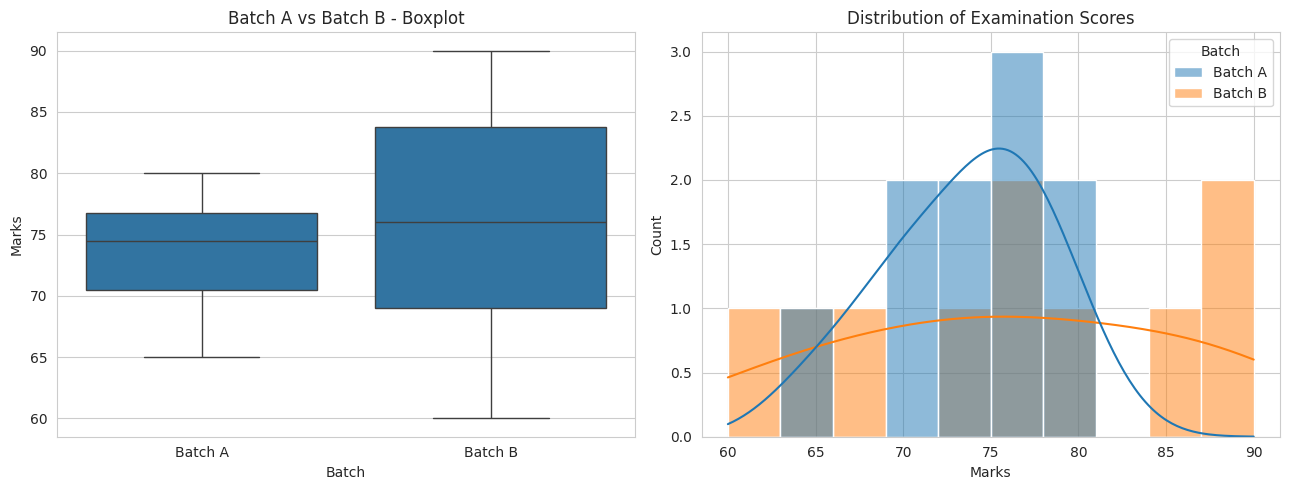

In [35]:

# Create DataFrame

batch_data = pd.DataFrame({
    "Marks": np.concatenate([batch_A, batch_B]),
    "Batch": (
        ["Batch A"] * len(batch_A) +
        ["Batch B"] * len(batch_B)
    )
})

# Create visualization

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot
sns.boxplot(
    data=batch_data,
    x="Batch",
    y="Marks",
    ax=axes[0]
)

axes[0].set_title("Batch A vs Batch B - Boxplot")

# Histogram
sns.histplot(
    data=batch_data,
    x="Marks",
    hue="Batch",
    kde=True,
    bins=10,
    ax=axes[1]
)

axes[1].set_title("Distribution of Examination Scores")

plt.tight_layout()
plt.show()


In [36]:

# Create final summary

final_summary = pd.DataFrame({
    "Batch A": [
        mean_A,
        median_A,
        std_A,
        ci_A[0],
        ci_A[1]
    ],

    "Batch B": [
        mean_B,
        median_B,
        std_B,
        ci_B[0],
        ci_B[1]
    ]

}, index=[
    "Mean",
    "Median",
    "Standard Deviation",
    "95% CI Lower Limit",
    "95% CI Upper Limit"
])

print("FINAL STATISTICAL SUMMARY:")
display(final_summary)

print("\nLevene Test P-value:", levene_test.pvalue)
print("T-test Statistic:", t_test.statistic)
print("T-test P-value:", t_test.pvalue)


FINAL STATISTICAL SUMMARY:


,Batch A,Batch B
Mean,73.600000,76.000000
Median,74.500000,76.000000
Standard Deviation,4.599517,9.977753
95% CI Lower Limit,70.309704,68.862345
95% CI Upper Limit,76.890296,83.137655



Levene Test P-value: 0.03256930083366206
T-test Statistic: -0.6907766008080042
T-test P-value: 0.5021756803938127


The examination scores of Batch A and Batch B were analyzed using descriptive and inferential statistics. Mean, median and standard deviation were calculated for both batches. The 95% confidence intervals were calculated using the t-distribution. Levene's test was performed to check equality of variances. Based on its result, the appropriate two-sample t-test was selected. The p-value was compared with the significance level of 0.05 to determine whether a statistically significant difference exists between the two batches.